In [ ]:
# Normal Distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Style1: Histogram

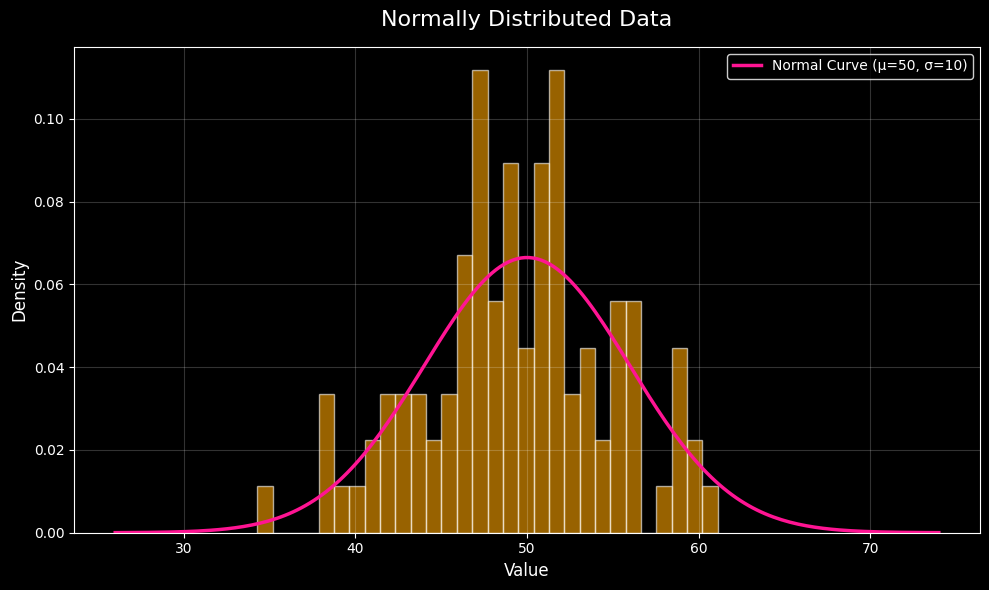

In [2]:
# step1: 1 Histogram

np.random.seed(42)  # for reproducibility
mu = 50     # mean
sigma = 6  # standard deviation
n= 100    # 10, 50, 100, 500, 1000 160, ,   number of data points
    
data = np.random.normal(mu, sigma, n)

plt.style.use('dark_background')  # Black background
plt.figure(figsize=(10, 6))

plt.hist(data, bins=30, density=True, color='orange', alpha=0.6, edgecolor='white')

# Theoretical normal curve
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
y = (1/(sigma * np.sqrt(2*np.pi))) * np.exp(-0.5 * ((x - mu)/sigma)**2)
plt.plot(x, y, color='#FF1493', linewidth=2.5, label='Normal Curve (μ=50, σ=10)')

# Styling
plt.title("Normally Distributed Data", fontsize=16, color='white', pad=15)
plt.xlabel("Value", fontsize=12, color='white')
plt.ylabel("Density", fontsize=12, color='white')
plt.grid(alpha=0.2)
plt.legend(facecolor='black', edgecolor='white', fontsize=10)
plt.tight_layout()

plt.show()


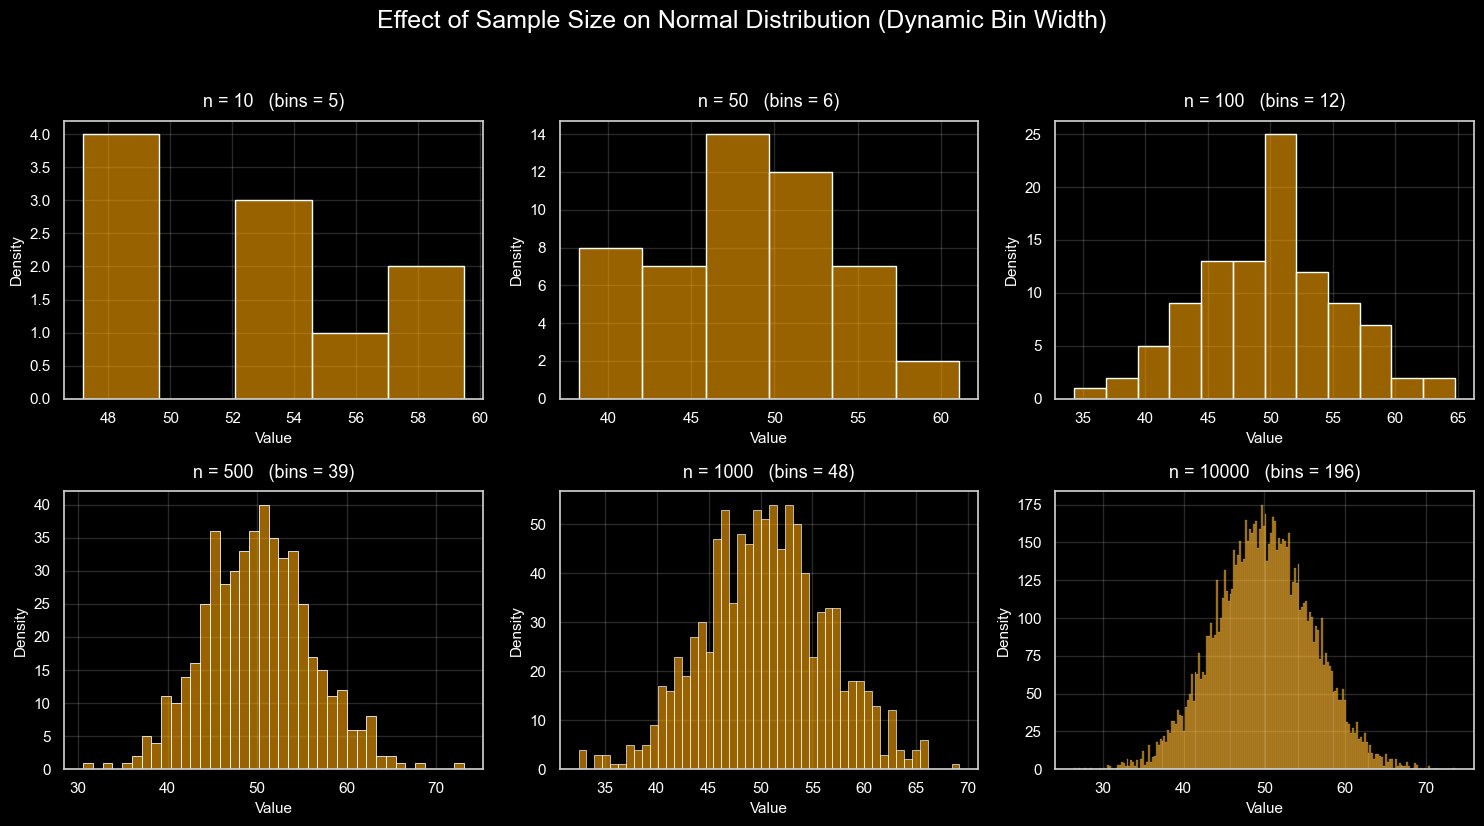

In [3]:

# Step 1: Setup
np.random.seed(42)
mu = 50
sigma = 6
sizes = [10, 50, 100, 500, 1000, 10000]

# Seaborn + dark background style
plt.style.use('dark_background')
sns.set(style='whitegrid', rc={'axes.facecolor':'black', 'figure.facecolor':'black'})

# Step 2: Create subplots (2 rows × 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

# Step 3: Plot each distribution with dynamic bin width
for i, n in enumerate(sizes):
    data = np.random.normal(mu, sigma, n)
    
    # Dynamic bin calculation (Scott’s or Freedman–Diaconis can also be used)
    # Here we simply make bin width proportional to sample size
    bin_width = sigma * 4 / np.sqrt(n)     # narrower bins as n grows
    bins = int((max(data) - min(data)) / bin_width)
    bins = max(5, bins)                    # ensure minimum bins
    
    sns.histplot(
        data, bins=bins, 
        # kde=True,
        color='orange', edgecolor='white', alpha=0.6, ax=axes[i]
    )
    
    # Labels and formatting
    axes[i].set_title(f"n = {n}   (bins = {bins})", fontsize=13, color='white', pad=10)
    axes[i].set_xlabel("Value", fontsize=11, color='white')
    axes[i].set_ylabel("Density", fontsize=11, color='white')
    axes[i].grid(alpha=0.2)
    axes[i].tick_params(colors='white')

# Step 4: Adjust layout
plt.suptitle("Effect of Sample Size on Normal Distribution (Dynamic Bin Width)", 
             fontsize=18, color='white', y=1.03)
plt.tight_layout()
plt.show()


### Style2 Stem plot

C:\Users\hi\AppData\Local\Temp\ipykernel_13648\531067166.py:35: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(facecolor='black', edgecolor='white', fontsize=10)


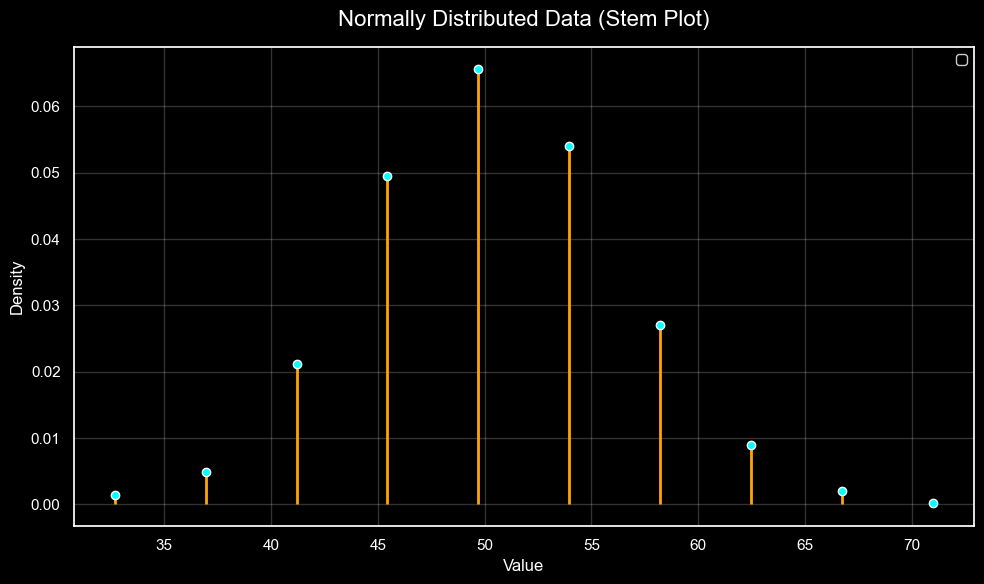

In [4]:
# Stem plot

# Plot with dark background
plt.style.use('dark_background')
plt.figure(figsize=(10, 6))

# Generate Normally Distributed Data
np.random.seed(42)
mu    = 50
sigma = 6
n     = 2000
data = np.random.normal(mu, sigma, n)

# Compute histogram data (for stem)
counts, bin_edges = np.histogram(data, density=True)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

# Stem plot
(markerline, stemlines, baseline) = plt.stem(
    bin_centers, counts, linefmt='orange', markerfmt='o', basefmt=' ',
)
plt.setp(markerline, markersize=6, markerfacecolor='cyan', markeredgecolor='white')
plt.setp(stemlines, linewidth=2)

# (OPTIONA) Theoretical normal curve
# x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)
# y = (1/(sigma * np.sqrt(2*np.pi))) * np.exp(-0.5 * ((x - mu)/sigma)**2)
# plt.plot(x, y, color='#FF1493', linewidth=2.5, label='Normal Curve (μ=50, σ=10)')

# Styling
plt.title("Normally Distributed Data (Stem Plot)", fontsize=16, color='white', pad=15)
plt.xlabel("Value", fontsize=12, color='white')
plt.ylabel("Density", fontsize=12, color='white')
plt.grid(alpha=0.2)
plt.legend(facecolor='black', edgecolor='white', fontsize=10)
plt.tight_layout()

# Show
plt.show()

# An example

In [18]:
# 1) Generate data
import numpy as np

# Following could be age of employees in a company
data = np.array([51, 55, 55, 55, 56, 56, 57, 57, 57, 57, 58, 58, 59, 59, 59,
    59, 59, 60, 60, 60, 61, 61, 61, 61, 61, 61, 62, 62, 62, 62, 62, 62, 62,
    62, 62, 62, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 64, 64, 64,
    64, 64, 64, 65, 65, 65, 65, 65, 65, 65, 65, 66, 66, 66, 66, 66, 66, 66,
    66, 66, 66, 66, 66, 66, 67, 67, 67, 68, 68, 68, 68, 69, 69, 69, 69, 69,
    69, 69, 70, 70, 70, 71, 72, 72, 72, 72, 72, 72, 74]
)

data = np.sort(data.astype(int))
print("data:\n", ", ".join(map(str, data)))

data:
 51, 55, 55, 55, 56, 56, 57, 57, 57, 57, 58, 58, 59, 59, 59, 59, 59, 60, 60, 60, 61, 61, 61, 61, 61, 61, 62, 62, 62, 62, 62, 62, 62, 62, 62, 62, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 64, 64, 64, 64, 64, 64, 65, 65, 65, 65, 65, 65, 65, 65, 66, 66, 66, 66, 66, 66, 66, 66, 66, 66, 66, 66, 66, 67, 67, 67, 68, 68, 68, 68, 69, 69, 69, 69, 69, 69, 69, 70, 70, 70, 71, 72, 72, 72, 72, 72, 72, 74


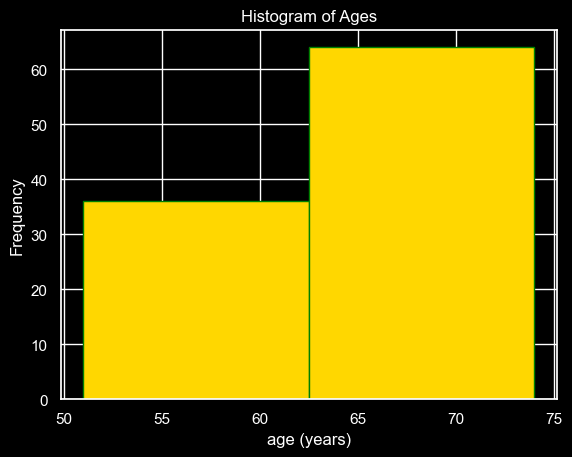

bins  : [51.  62.5 74. ]
counts: [36. 64.]


In [22]:
# 3) Prettify

bin_count = 2
counts, bins, patches = plt.hist( data, bins=bin_count,
    edgecolor='green',         # green edges for contrast
    color='gold'               # brighter color for visibility
)

plt.title('Histogram of Ages', color='white')
plt.xlabel('age (years)', color='white')
plt.ylabel('Frequency', color='white')
plt.tick_params(colors='white')

plt.show()

print(f"bins  : {np.round(bins,1)}")
print(f"counts: {counts}")

## Observation about bin size
Here **bin_width = (max_value - min_value)/num_of_bins = (74-51)/2 = 11.5**.
- The bin starts from minimum value, which is 51, and then increase by 11.5 units. 
- The bins go from 51 -> 62.5 -> 74
- bin 51-62.5 contains 36 elements, bin 62.5-74 contains 64 elements

**Lets use above and increase the number of bins**

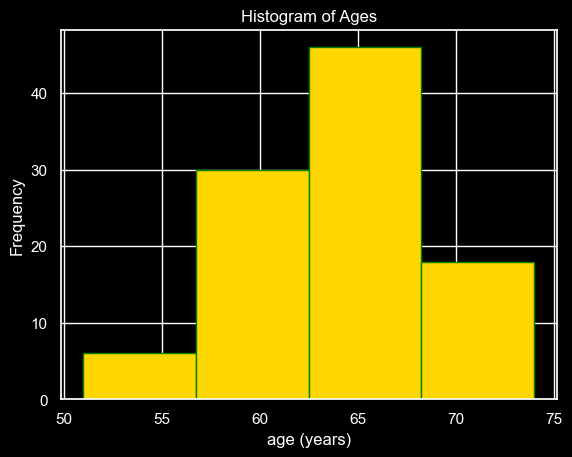

bins  : [51.  56.8 62.5 68.2 74. ]
counts: [ 6. 30. 46. 18.]


In [20]:
# 2) Lets increase the bin count to 4

bin_count = 4
counts, bins, patches = plt.hist( data, bins=bin_count,
    edgecolor='green',         # green edges for contrast
    color='gold'               # brighter color for visibility
)

plt.title('Histogram of Ages', color='white')
plt.xlabel('age (years)', color='white')
plt.ylabel('Frequency', color='white')
plt.tick_params(colors='white')

plt.show()

print(f"bins  : {np.round(bins,1)}")
print(f"counts: {counts}")

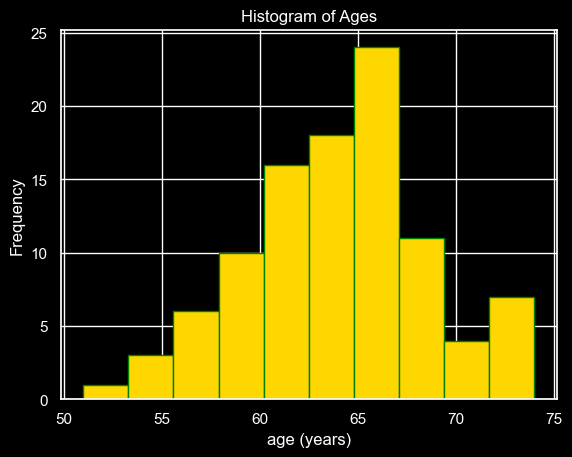

bins  : [51.  53.3 55.6 57.9 60.2 62.5 64.8 67.1 69.4 71.7 74. ]
counts: [ 1.  3.  6. 10. 16. 18. 24. 11.  4.  7.]


In [ ]:
# 3)  Lets increase the bin count to 10
im
bin_count = 10
counts, bins, patches = plt.hist( data, bins=bin_count,
    edgecolor='green',         # green edges for contrast
    color='gold'               # brighter color for visibility
)

plt.title('Histogram of Ages', color='white')
plt.xlabel('age (years)', color='white')
plt.ylabel('Frequency', color='white')
plt.tick_params(colors='white')

plt.show()

print(f"bins  : {np.round(bins,1)}")
print(f"counts: {counts}")

In [ ]:
# Another example

In [28]:
# load dataset
df = sns.load_dataset("tips")

# see columns
print(df.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


In [30]:
print(sorted(df['total_bill'].to_list()))

[3.07, 5.75, 7.25, 7.25, 7.51, 7.56, 7.74, 8.35, 8.51, 8.52, 8.58, 8.77, 9.55, 9.6, 9.68, 9.78, 9.94, 10.07, 10.07, 10.09, 10.27, 10.29, 10.33, 10.33, 10.34, 10.34, 10.51, 10.59, 10.63, 10.65, 10.77, 11.02, 11.17, 11.24, 11.35, 11.38, 11.59, 11.61, 11.69, 11.87, 12.02, 12.03, 12.16, 12.26, 12.43, 12.46, 12.48, 12.54, 12.6, 12.66, 12.69, 12.74, 12.76, 12.9, 13.0, 13.0, 13.03, 13.13, 13.16, 13.27, 13.28, 13.37, 13.39, 13.42, 13.42, 13.42, 13.51, 13.81, 13.81, 13.94, 14.0, 14.07, 14.15, 14.26, 14.31, 14.48, 14.52, 14.73, 14.78, 14.83, 15.01, 15.04, 15.06, 15.36, 15.38, 15.42, 15.48, 15.53, 15.69, 15.69, 15.77, 15.81, 15.95, 15.98, 15.98, 16.0, 16.04, 16.21, 16.27, 16.29, 16.31, 16.32, 16.4, 16.43, 16.45, 16.47, 16.49, 16.58, 16.66, 16.82, 16.93, 16.97, 16.99, 17.07, 17.26, 17.29, 17.31, 17.46, 17.47, 17.51, 17.59, 17.78, 17.81, 17.82, 17.89, 17.92, 17.92, 18.04, 18.15, 18.24, 18.26, 18.28, 18.29, 18.29, 18.35, 18.43, 18.64, 18.69, 18.71, 18.78, 19.08, 19.44, 19.49, 19.65, 19.77, 19.81, 19

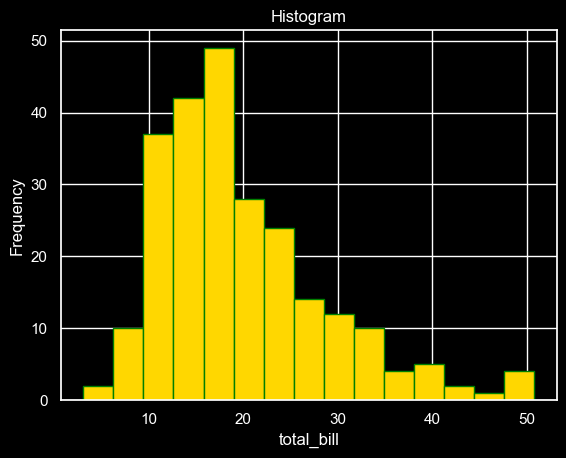

bins  : [ 3.1  6.3  9.4 12.6 15.8 19.  22.2 25.3 28.5 31.7 34.9 38.1 41.3 44.4
 47.6 50.8]
counts: [ 2. 10. 37. 42. 49. 28. 24. 14. 12. 10.  4.  5.  2.  1.  4.]


In [32]:

data = sorted(df['total_bill'].to_list())

bin_count = 15
counts, bins, patches = plt.hist( data, bins=bin_count,
    edgecolor='green',         # green edges for contrast
    color='gold'               # brighter color for visibility
)

plt.title('Histogram', color='white')
plt.xlabel('total_bill', color='white')
plt.ylabel('Frequency', color='white')
plt.tick_params(colors='white')

plt.show()

print(f"bins  : {np.round(bins,1)}")
print(f"counts: {counts}")

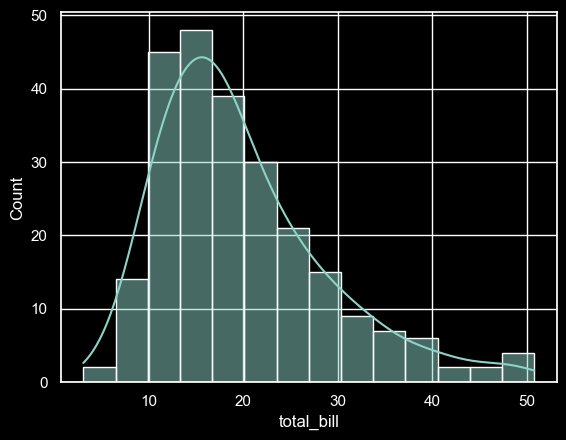

In [31]:
sns.histplot(df["total_bill"], kde=True)

plt.show()